# Cross-Lingual Alignment Analysis: $\Delta_{\text{TS-TF}}$ & Layer-Wise Breakdown
This notebook extends your existing XCOPA / Belebele evaluation workflow for **Llama3.2-1B** to:
1. Separate **Transfer Success (TS)** and **Transfer Failure (TF)** samples.
2. Compute $\lambda_{\max}$ (or load your existing `max_lamda_df`) and $\Delta_{\text{TS-TF}}$ with one-sided z-test $p$-values across **DALI**, **DALI-Strong**, and **MEXA**.
3. Generate a **paper-style summary table** with significance markers (`*`, `**`, `***`).
4. Plot a **grouped bar chart** comparing $\Delta_{\text{TS-TF}}$ across languages and metrics.
5. Plot **layer-wise (Layers 0–16) TS vs. TF alignment curves** to see where the alignment gap opens up.
6. Export **TF sample indices** for downstream **activation patching**.


## 1. Imports & Configuration


In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from statsmodels.stats.proportion import proportions_ztest

# --- Configuration ---
LLM_NAME = "Llama3.2-1B"
TASK = "xcopa"  # Change to "belebele" when running on Belebele
NUM_SAMPLES = 167 if TASK == "xcopa" else 300
NUM_LAYERS = 17  # Layers 0..16 for Llama3.2-1B

ACCURACY_BASE_DIR = Path("../results/accuracy")
ALIGNMENT_BASE_DIR = Path("../alignment_results")
PATCHING_EXPORT_DIR = Path(f"../results/patching/{LLM_NAME}/{TASK}")

# Map alignment filenames -> accuracy file ISO codes
LANG_MAP = {
    "italian": "it",
    "thai": "th",
}

METRICS = ["dali", "dali_strong", "mexa"]


## 2. Separate Transfer Success (TS) and Transfer Failure (TF)


In [2]:
def separate_ts_tf(lang_code, num_samples=NUM_SAMPLES, llm_name=LLM_NAME, task=TASK, base_dir=ACCURACY_BASE_DIR):
    folder = base_dir / llm_name / task
    eng_df = pd.read_json(folder / f"{task}_eval_{llm_name}_translation-{lang_code}_AB.jsonl", lines=True)
    lang_df = pd.read_json(folder / f"{task}_eval_{llm_name}_{lang_code}_AB.jsonl", lines=True)

    # Restrict to the samples present in your alignment JSONs
    eng_df = eng_df[eng_df["idx"] < num_samples]
    lang_df = lang_df[lang_df["idx"] < num_samples]

    merged = eng_df[["idx", "acc"]].merge(
        lang_df[["idx", "acc"]],
        on="idx",
        suffixes=("_eng", "_lang")
    )

    ts_df = merged[(merged["acc_eng"] == 1.0) & (merged["acc_lang"] == 1.0)].reset_index(drop=True)
    tf_df = merged[(merged["acc_eng"] == 1.0) & (merged["acc_lang"] == 0.0)].reset_index(drop=True)
    return ts_df, tf_df

# Quick check
ts_tf_splits = {}
for align_lang, eval_lang in LANG_MAP.items():
    ts_df, tf_df = separate_ts_tf(eval_lang)
    ts_tf_splits[align_lang] = (ts_df, tf_df)
    print(f"{align_lang:10s} ({eval_lang}): n_TS = {len(ts_df):3d}, n_TF = {len(tf_df):3d}")


italian    (it): n_TS =  51, n_TF =  44
thai       (th): n_TS =  55, n_TF =  17


## 3. Load Alignment Matrices & Compute $\Delta_{\text{TS-TF}}$


In [ ]:
def load_alignment_df(align_json_path, num_layers=NUM_LAYERS):
    align_df = pd.read_json(align_json_path)
    # Ensure rows = layers (17) and columns = samples
    if align_df.shape[0] != num_layers and align_df.shape[1] == num_layers:
        align_df = align_df.T
    return align_df

def find_alignment_file(metric, align_lang, llm_name=LLM_NAME, task=TASK, base_dir=ALIGNMENT_BASE_DIR):
    files = list((base_dir / llm_name / task / metric).glob(f"*{align_lang}*.json"))
    return files[0] if files else None

def compute_delta_at_layer(align_df, ts_df, tf_df, layer_idx):
    # Handle 0-based (0..N-1) vs 1-based (1..N) column keys automatically
    offset = 1 if 0 not in align_df.columns else 0
    ts_cols = [c for c in (ts_df["idx"] + offset) if c in align_df.columns]
    tf_cols = [c for c in (tf_df["idx"] + offset) if c in align_df.columns]

    ts_align = align_df.loc[layer_idx, ts_cols]
    tf_align = align_df.loc[layer_idx, tf_cols]

    delta = (ts_align.mean() - tf_align.mean()) * 100
    _, p_val = proportions_ztest(
        [ts_align.sum(), tf_align.sum()],
        [len(ts_align), len(tf_align)],
        alternative="larger"
    )

    return {
        "n_TS": len(ts_align),
        "n_TF": len(tf_align),
        "TS_align_%": round(ts_align.mean() * 100, 2),
        "TF_align_%": round(tf_align.mean() * 100, 2),
        "Delta_TS_TF_%": round(delta, 2),
        "p_value": round(float(p_val), 4),
    }

# Compute lambda_max automatically (layer with highest mean alignment) and evaluate Delta_TS_TF
results = []
for align_lang in LANG_MAP.keys():
    ts_df, tf_df = ts_tf_splits[align_lang]
    for metric in METRICS:
        json_path = find_alignment_file(metric, align_lang)
        if json_path is None:
            print(f"[Skipping] Missing file for {metric} - {align_lang}")
            continue

        align_df = load_alignment_df(json_path)
        
        lambda_max = int(align_df.mean(axis=1).idxmax())

        stats = compute_delta_at_layer(align_df, ts_df, tf_df, lambda_max)
        results.append({
            "language": align_lang,
            "metric": metric,
            "lambda_max": lambda_max,
            **stats
        })

delta_df = pd.DataFrame(results)
delta_df


,language,metric,lambda_max,n_TS,n_TF,TS_align_%,TF_align_%,Delta_TS_TF_%,p_value
0,italian,dali,5,51,44,82.35,59.09,23.26,0.0061
1,italian,dali_strong,0,51,44,1.96,2.27,-0.31,0.5421
2,italian,mexa,7,51,44,74.51,75.00,-0.49,0.5219
3,thai,dali,5,55,17,38.18,23.53,14.65,0.1337
4,thai,dali_strong,5,55,17,12.73,0.00,12.73,0.0608
5,thai,mexa,5,55,17,36.36,41.18,-4.81,0.6399


## 4. Paper-Style Summary Table (with Significance Markers)


In [8]:
def sig_stars(p):
    if pd.isna(p):
        return ""
    if p < 0.001:
        return "***"
    if p < 0.01:
        return "**"
    if p < 0.05:
        return "*"
    return ""

delta_df["formatted"] = delta_df.apply(
    lambda r: f"{r['Delta_TS_TF_%']:+.2f}{sig_stars(r['p_value'])} (L{r['lambda_max']})",
    axis=1
)

summary_table = delta_df.pivot(index="language", columns="metric", values="formatted")
display(summary_table)



metric,dali,dali_strong,mexa
language,,,
italian,+23.26** (L5),-0.31 (L0),-0.49 (L7)
thai,+14.65 (L5),+12.73 (L5),-4.81 (L5)


## 5. Grouped Bar Chart: $\Delta_{\text{TS-TF}}$ Across Languages & Metrics


<>:31: SyntaxWarning: invalid escape sequence '\D'
<>:31: SyntaxWarning: invalid escape sequence '\l'
<>:31: SyntaxWarning: invalid escape sequence '\m'
<>:31: SyntaxWarning: invalid escape sequence '\D'
<>:31: SyntaxWarning: invalid escape sequence '\l'
<>:31: SyntaxWarning: invalid escape sequence '\m'
C:\Users\cream\AppData\Local\Temp\ipykernel_42744\3054415976.py:31: SyntaxWarning: invalid escape sequence '\D'
  ax.set_title(f"{LLM_NAME} on {TASK.upper()}: Alignment Gap ($\Delta_{{\text{{TS-TF}}}}$) at $\lambda_{{\max}}$")
C:\Users\cream\AppData\Local\Temp\ipykernel_42744\3054415976.py:31: SyntaxWarning: invalid escape sequence '\l'
  ax.set_title(f"{LLM_NAME} on {TASK.upper()}: Alignment Gap ($\Delta_{{\text{{TS-TF}}}}$) at $\lambda_{{\max}}$")
C:\Users\cream\AppData\Local\Temp\ipykernel_42744\3054415976.py:31: SyntaxWarning: invalid escape sequence '\m'
  ax.set_title(f"{LLM_NAME} on {TASK.upper()}: Alignment Gap ($\Delta_{{\text{{TS-TF}}}}$) at $\lambda_{{\max}}$")


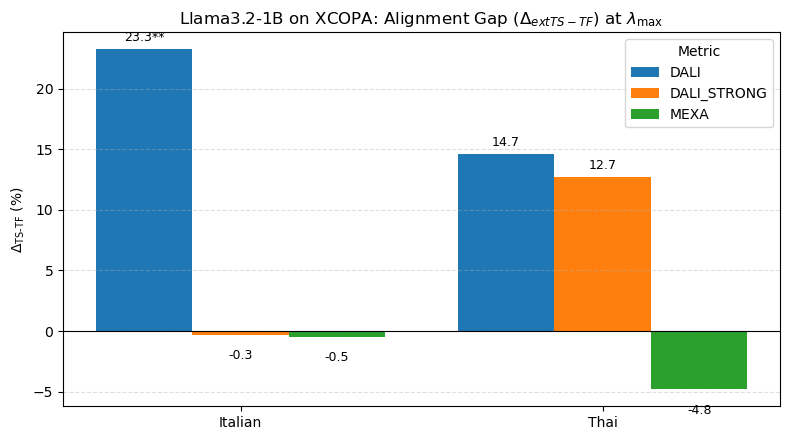

In [5]:
if not delta_df.empty:
    pivot_delta = delta_df.pivot(index="language", columns="metric", values="Delta_TS_TF_%")
    pivot_pval = delta_df.pivot(index="language", columns="metric", values="p_value")

    languages = pivot_delta.index.tolist()
    available_metrics = pivot_delta.columns.tolist()
    x = np.arange(len(languages))
    width = 0.8 / max(len(available_metrics), 1)

    fig, ax = plt.subplots(figsize=(8, 4.5))
    for i, metric in enumerate(available_metrics):
        vals = pivot_delta[metric].values
        pvals = pivot_pval[metric].values
        bars = ax.bar(x + i * width - (len(available_metrics) - 1) * width / 2, vals, width, label=metric.upper())

        # Annotate bars with value + significance stars
        for bar, val, pv in zip(bars, vals, pvals):
            if pd.notna(val):
                offset_y = 0.4 if val >= 0 else -1.2
                ax.text(
                    bar.get_x() + bar.get_width() / 2,
                    val + offset_y,
                    f"{val:.1f}{sig_stars(pv)}",
                    ha="center", va="bottom" if val >= 0 else "top", fontsize=9
                )

    ax.axhline(0, color="black", linewidth=0.8)
    ax.set_xticks(x)
    ax.set_xticklabels([l.capitalize() for l in languages])
    ax.set_ylabel(r"$\Delta_{\text{TS-TF}}$ (%)")
    ax.set_title(f"{LLM_NAME} on {TASK.upper()}: Alignment Gap ($\Delta_{{\text{{TS-TF}}}}$) at $\lambda_{{\max}}$")
    ax.legend(title="Metric")
    ax.grid(axis="y", linestyle="--", alpha=0.4)
    plt.tight_layout()
    plt.show()


## 6. Layer-Wise TS vs. TF Alignment Curves (Layers 0–16)
Check where in the network the alignment gap between Transfer Success and Transfer Failure actually opens up.


<>:29: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\m'
<>:29: SyntaxWarning: invalid escape sequence '\l'
<>:29: SyntaxWarning: invalid escape sequence '\m'
C:\Users\cream\AppData\Local\Temp\ipykernel_42744\2794958526.py:29: SyntaxWarning: invalid escape sequence '\l'
  ax.axvline(lambda_max, color="gray", linestyle=":", label=f"$\lambda_{{\max}}$ = {lambda_max}")
C:\Users\cream\AppData\Local\Temp\ipykernel_42744\2794958526.py:29: SyntaxWarning: invalid escape sequence '\m'
  ax.axvline(lambda_max, color="gray", linestyle=":", label=f"$\lambda_{{\max}}$ = {lambda_max}")


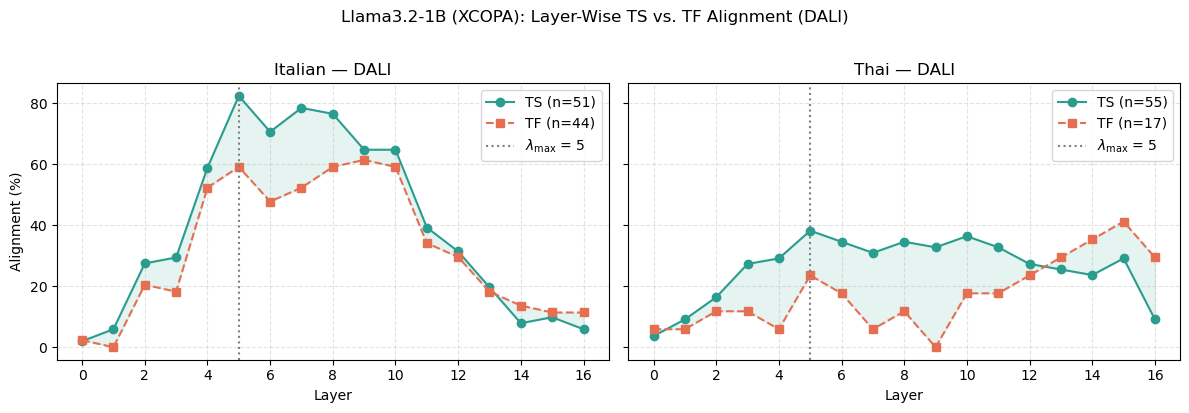

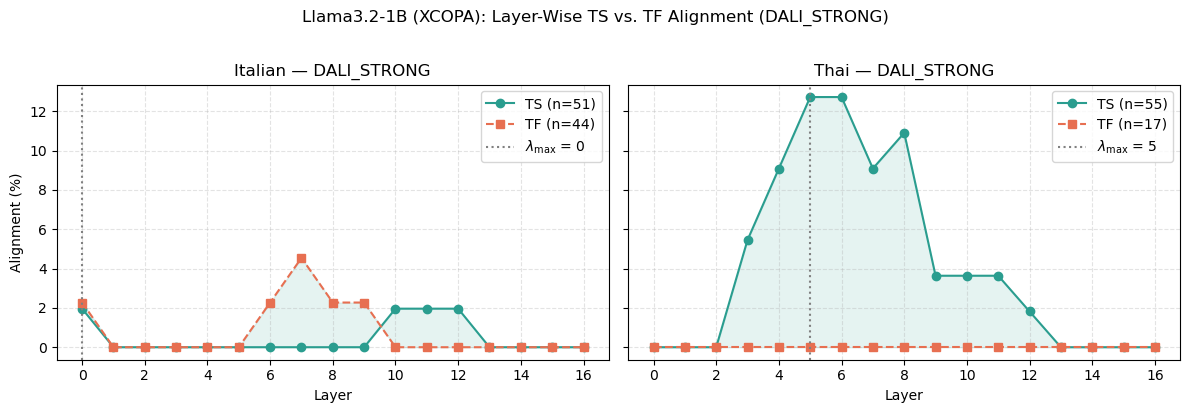

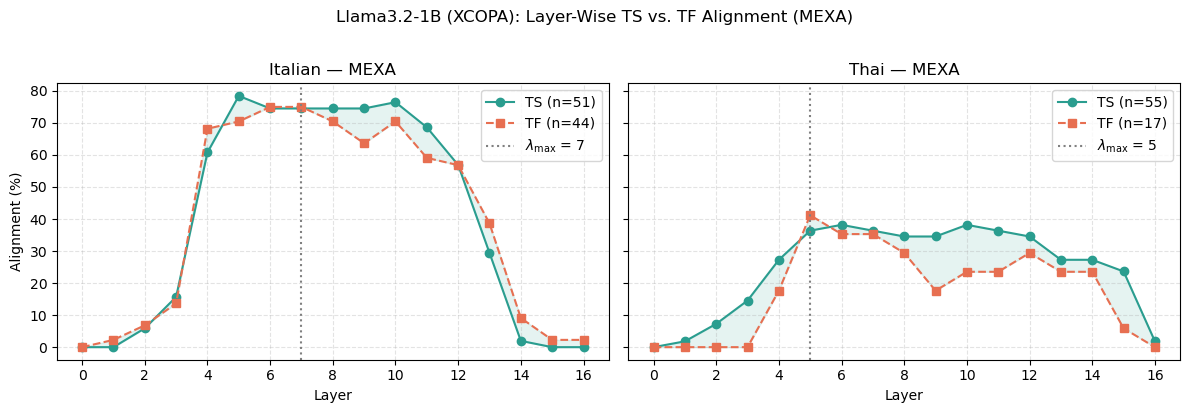

In [6]:
def compute_layerwise_curves(align_df, ts_df, tf_df):
    offset = 1 if 0 not in align_df.columns else 0
    ts_cols = [c for c in (ts_df["idx"] + offset) if c in align_df.columns]
    tf_cols = [c for c in (tf_df["idx"] + offset) if c in align_df.columns]

    ts_curve = align_df[ts_cols].mean(axis=1) * 100
    tf_curve = align_df[tf_cols].mean(axis=1) * 100
    return ts_curve, tf_curve

# Plot for each available metric
for metric in METRICS:
    valid_langs = [l for l in LANG_MAP.keys() if find_alignment_file(metric, l) is not None]
    if not valid_langs:
        continue

    fig, axes = plt.subplots(1, len(valid_langs), figsize=(6 * len(valid_langs), 4), sharey=True)
    if len(valid_langs) == 1:
        axes = [axes]

    for ax, align_lang in zip(axes, valid_langs):
        align_df = load_alignment_df(find_alignment_file(metric, align_lang))
        ts_df, tf_df = ts_tf_splits[align_lang]
        ts_curve, tf_curve = compute_layerwise_curves(align_df, ts_df, tf_df)
        lambda_max = int(align_df.mean(axis=1).idxmax())

        layers = align_df.index
        ax.plot(layers, ts_curve, marker="o", label=f"TS (n={len(ts_df)})", color="#2a9d8f")
        ax.plot(layers, tf_curve, marker="s", linestyle="--", label=f"TF (n={len(tf_df)})", color="#e76f51")
        ax.axvline(lambda_max, color="gray", linestyle=":", label=f"$\lambda_{{\max}}$ = {lambda_max}")
        ax.fill_between(layers, tf_curve, ts_curve, alpha=0.12, color="#2a9d8f")

        ax.set_title(f"{align_lang.capitalize()} — {metric.upper()}")
        ax.set_xlabel("Layer")
        ax.set_xticks(range(0, NUM_LAYERS, 2))
        ax.grid(True, linestyle="--", alpha=0.35)
        ax.legend()

    axes[0].set_ylabel("Alignment (%)")
    fig.suptitle(f"{LLM_NAME} ({TASK.upper()}): Layer-Wise TS vs. TF Alignment ({metric.upper()})", y=1.02)
    plt.tight_layout()
    plt.show()


## 7. Export TF Sample Indices for Causal Activation Patching
Saves the exact Transfer Failure (`idx`) lists so you can patch English activations into the target-language forward pass at $\lambda_{\max}$.


In [7]:
PATCHING_EXPORT_DIR.mkdir(parents=True, exist_ok=True)

for align_lang, (ts_df, tf_df) in ts_tf_splits.items():
    out_file = PATCHING_EXPORT_DIR / f"{align_lang}_tf_indices.json"
    payload = {
        "llm": LLM_NAME,
        "task": TASK,
        "language": align_lang,
        "num_samples_evaluated": NUM_SAMPLES,
        "n_TS": len(ts_df),
        "n_TF": len(tf_df),
        "tf_indices": tf_df["idx"].astype(int).tolist(),
        "ts_indices": ts_df["idx"].astype(int).tolist(),
    }
    with open(out_file, "w") as f:
        json.dump(payload, f, indent=2)
    print(f"Saved {len(tf_df)} TF indices -> {out_file}")


Saved 44 TF indices -> ..\results\patching\Llama3.2-1B\xcopa\italian_tf_indices.json
Saved 17 TF indices -> ..\results\patching\Llama3.2-1B\xcopa\thai_tf_indices.json
